# EntregaCerta AI — doses de CTGAN e repetição de atrasos reais

Experimento de 11/11/2026, separado do modelo da aplicação. **Avaliação somente em pedidos reais.**

Pergunta: adicionar 500, 1.000 ou 2.000 exemplos de atraso melhora a regressão logística?
Comparamos repetição de positivos, CTGAN treinada nos positivos e CTGAN treinada em ambas
as classes com geração condicionada a atraso. Sementes **7, 42 e 123**.

Os resultados são históricos, com o alvo conhecido de entrega após o **dia** prometido.
Scores não são probabilidades calibradas. Nenhum experimento comprova redução operacional
de atrasos. Os registros sintéticos continuam identificados como artificiais.

## Resultado medido

**Melhor média de F1 na validação: Somente reais, com 0 exemplos adicionais.**
F1 = **0.2697**, AP = **0.1986**.
São 28 ajustes de regressão logística; nove configurações com acréscimo avaliadas em três sementes
e um baseline fixo. O notebook 02 e o modelo da aplicação permanecem preservados.

A melhor configuração CTGAN pela validação foi **CTGAN condicional +500**:
F1 médio **0.2640**, mínimo–máximo **0.2638–0.2644**,
AP médio **0.1873**. Baseline: F1 **0.2697** e AP **0.1986**.
O desempenho pertence ao orçamento de aproximadamente 900 atualizações por GAN;
não é uma conclusão sobre todas as configurações possíveis dessa arquitetura.

**A rodada não justificou adotar CTGAN no treinamento principal.**


## Contexto e método

- Fonte: PostgreSQL, `public.vw_pedidos_inferencia JOIN public.pedidos`, apenas partições reais.
- Unidade: pedido. Entradas: 29 atributos disponíveis na aprovação, sob as hipóteses do projeto.
- Cortes temporais: 01/01/2018 e 01/05/2018; preservada a seleção atual de rótulos conhecidos.
- Pré-processador ajustado uma vez no treino real; 159 colunas resultantes, compartilhadas.
- Regressão logística: `C=1`, `solver=liblinear`, `max_iter=1500`, `random_state=42`, sem pesos.
- Critério pré-definido: F1 médio de validação; desempate por AP. Limiar por execução escolhido
  exclusivamente na validação. A fila operacional de 10% tem métricas próprias.
- Doses são prefixos de um lote por semente: 500 ⊂ 1.000 ⊂ 2.000. Repetição usa reposição.
- CTGAN: lote 500, redes (128,128), `pac=10`, CPU. Aproximadamente o mesmo orçamento:
  positivos = 300 épocas × 3 lotes = **900 atualizações**; condicional = 11 × 82 = **902**.
  Isso é um teste inicial de orçamento limitado, não uma busca exaustiva de convergência.
- Gerador positivo da seed 42 reaproveitado do experimento anterior; seeds 7/123 retreinadas.
  Os três geradores condicionais foram treinados com todos os 41.173 pedidos reais de treino.
- Condicionar a CTGAN favorece, mas não garante o rótulo: a amostragem rejeita `atrasou != 1`.
  Não relabelamos negativos gerados. IDs/datas de entrega não entram no gerador/classificador.
- Intervalos entre sementes representam variação experimental, **não intervalos de confiança**.

### Limitações que continuam valendo

Só há pedidos entregues elegíveis; a purga temporal pode excluir atrasos longos.
O teste histórico já foi consultado no projeto: seus resultados são **descritivos**.
Não escolhemos dose, semente, limiar ou arquitetura por ele. Para confirmação independente,
será necessário outro período reservado. A mudança de frequência de atraso entre períodos
e a falta de informações operacionais não são resolvidas automaticamente por uma GAN.

### 1. Carregar evidências executadas

Kernel: `.venv-ctgan/Scripts/python.exe` (dependências em `requirements-ctgan.txt`).
Este notebook lê os resultados do script reproduzível, sem repetir treinamentos caros ao abrir.
Para executar todo o experimento novamente, da raiz do projeto, com PostgreSQL ligado:

```powershell
./.venv-ctgan/Scripts/python.exe -m experimentos.testar_doses_ctgan --snapshot --saida Modelos/experimento_ctgan/doses_ponto1
```

O script consulta o banco somente para leitura e verifica o protocolo antes de reutilizar caches.
`--snapshot` permite retomar a cópia local explicitamente identificada. Saídas em
`Modelos/experimento_ctgan/doses_20261111/`. Não grava nas tabelas nem substitui o CSV anterior.
Para reproduzir os lotes desta rodada do zero, execute primeiro o notebook CTGAN de 10.000
exemplos: a seed 42 positiva reutiliza uma amostra desse lote. Sem esse cache, o script faz
nova amostragem da seed 42, e os resultados podem diferir. Preserve as versões do protocolo.

In [1]:
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experimentos/testar_doses_ctgan.py').is_file())
if str(raiz) not in sys.path: sys.path.insert(0, str(raiz))
from experimentos.testar_doses_ctgan import metricas
from experimentos.experimento_ctgan import hash_base, validar_injecao
from src.preparar_dados import COLUNAS_PREVISAO

pasta = raiz / 'Modelos/experimento_ctgan/doses_20261111'
val = pd.read_csv(pasta / 'metricas_validacao.csv')
teste = pd.read_csv(pasta / 'metricas_teste_descritivo.csv')
resumo_val = pd.read_csv(pasta / 'resumo_validacao.csv')
resumo_teste = pd.read_csv(pasta / 'resumo_teste_descritivo.csv')
evidencias = joblib.load(pasta / 'comparacao.joblib')
base = joblib.load(pasta / 'snapshot_postgresql.joblib')
assert len(val) == len(teste) == 28
assert hash_base(base) == evidencias['configuracao']['hash_base']
nomes = {'Real': 'Somente reais', 'Repeticao': 'Repetição',
         'CTGAN_positivos': 'CTGAN: positivos', 'CTGAN_condicional': 'CTGAN: condicional'}
cores = {'Repeticao': '#345E8A', 'CTGAN_positivos': '#AC6519', 'CTGAN_condicional': '#82713B'}
plt.rcParams.update({'font.size': 11, 'figure.figsize': (11, 5),
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Critério:', evidencias['configuracao']['criterio'])
print('Escolha congelada antes do teste:', evidencias['selecao'])

Critério: F1 medio na validacao; desempate AP; nenhuma selecao por teste
Escolha congelada antes do teste: {'metodo': 'Real', 'dose': 0, 'criterio': 'F1 medio na validacao; desempate AP; nenhuma selecao por teste', 'f1_medio': 0.26972332015810274}


### 2. Quantos pedidos reais sustentam a comparação?

In [2]:
coortes = base.groupby('particao').agg(pedidos=('order_id', 'size'), atrasos=('atrasou', 'sum'),
                                     inicio=('order_approved_at', 'min'), fim=('order_approved_at', 'max'))
coortes['taxa_atraso_%'] = 100 * coortes.atrasos / coortes.pedidos
display(coortes.round(2))
treino = base.loc[base.particao.eq('treino')]
display(pd.DataFrame([{'adicionados': d, 'total_treino': len(treino)+d,
    'positivos_treino': int(treino.atrasou.sum())+d,
    'taxa_positiva_%': 100*(treino.atrasou.sum()+d)/(len(treino)+d)}
    for d in [0, 500, 1000, 2000]]).round(2))
print('Preditores transformados:', len(evidencias['preprocessador'].get_feature_names_out()))
print('Fonte: consulta em experimentos/experimento_ctgan.py, função consultar_base().')

,pedidos,atrasos,inicio,fim,taxa_atraso_%
particao,,,,,
teste,25550,1124,2018-05-01 01:56:05,2018-08-29 15:10:26,4.40
treino,41173,1765,2016-09-15 12:16:38,2017-12-28 12:31:55,4.29
validacao,24667,2494,2018-01-01 02:30:25,2018-04-27 13:15:24,10.11


,adicionados,total_treino,positivos_treino,taxa_positiva_%
0,0,41173,1765,4.29
1,500,41673,2265,5.44
2,1000,42173,2765,6.56
3,2000,43173,3765,8.72


Preditores transformados: 159
Fonte: consulta em src/experimento_ctgan.py, função consultar_base().


### 3. Validação — médias das três sementes

O baseline sem acréscimo foi ajustado uma vez, porque permanece idêntico em todas as comparações.
Accuracy, precision, recall e F1 abaixo usam o **limiar que maximiza F1 na validação**.
AP considera a ordenação completa; “atrasos na fila” usa a capacidade fixa de 2.466 pedidos.

In [3]:
def tabela_legivel(resumo):
    cols = ['metodo', 'dose', 'accuracy_mean', 'precision_mean', 'recall_mean', 'f1_mean', 'AP_mean', 'atrasos_top10_mean']
    t = resumo[cols].copy()
    t['metodo'] = t.metodo.map(nomes)
    for c in ['accuracy_mean', 'precision_mean', 'recall_mean', 'f1_mean']:
        t[c] = t[c].map(lambda x: f'{100*x:.2f}%')
    t['AP_mean'] = t.AP_mean.round(4)
    t['atrasos_top10_mean'] = t.atrasos_top10_mean.round(1)
    return t.rename(columns={'metodo': 'Método', 'dose': 'Adicionados', 'accuracy_mean': 'Accuracy',
        'precision_mean': 'Precision', 'recall_mean': 'Recall', 'f1_mean': 'F1', 'AP_mean': 'AP',
        'atrasos_top10_mean': 'Atrasos na fila'})
display(tabela_legivel(resumo_val))

,Método,Adicionados,Accuracy,Precision,Recall,F1,AP,Atrasos na fila
0,CTGAN: condicional,500,78.86%,20.39%,37.50%,26.40%,0.1873,583.3
1,CTGAN: condicional,1000,74.12%,18.11%,43.69%,25.49%,0.1736,538.0
2,CTGAN: condicional,2000,66.98%,15.25%,49.39%,23.26%,0.1506,450.0
3,CTGAN: positivos,500,77.63%,19.64%,39.08%,26.11%,0.1860,576.7
4,CTGAN: positivos,1000,76.99%,19.03%,39.20%,25.61%,0.1794,556.3
5,CTGAN: positivos,2000,75.80%,18.33%,39.47%,24.85%,0.1694,523.0
6,Somente reais,0,81.27%,22.27%,34.20%,26.97%,0.1986,619.0
7,Repetição,500,80.36%,21.77%,35.86%,26.97%,0.1979,615.7
8,Repetição,1000,80.32%,21.54%,35.78%,26.87%,0.1967,613.3
9,Repetição,2000,78.56%,20.29%,38.28%,26.52%,0.1941,603.7


### 4. Dose e estabilidade — o acréscimo ajuda nas três sementes?

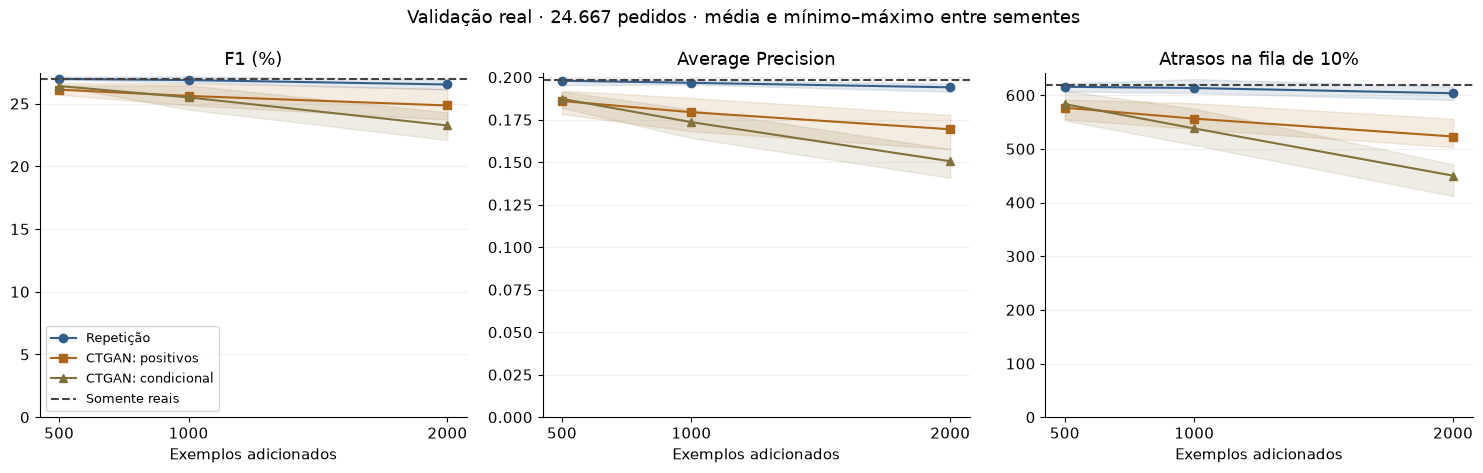

,metodo,dose,execucoes,f1_mean,f1_std,f1_min,f1_max,AP_mean
0,CTGAN_condicional,500,3,0.2640,0.0003,0.2638,0.2644,0.1873
1,CTGAN_condicional,1000,3,0.2549,0.0097,0.2453,0.2646,0.1736
2,CTGAN_condicional,2000,3,0.2326,0.0111,0.2210,0.2430,0.1506
3,CTGAN_positivos,500,3,0.2611,0.0048,0.2570,0.2664,0.1860
4,CTGAN_positivos,1000,3,0.2561,0.0090,0.2487,0.2662,0.1794
5,CTGAN_positivos,2000,3,0.2485,0.0123,0.2372,0.2616,0.1694
6,Real,0,1,0.2697,NaN,0.2697,0.2697,0.1986
7,Repeticao,500,3,0.2697,0.0015,0.2688,0.2714,0.1979
8,Repeticao,1000,3,0.2687,0.0025,0.2670,0.2717,0.1967
9,Repeticao,2000,3,0.2652,0.0040,0.2613,0.2693,0.1941


In [4]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.8))
referencia = resumo_val.loc[resumo_val.metodo.eq('Real')].iloc[0]
for ax, metrica, titulo, escala in zip(eixos, ['f1', 'AP', 'atrasos_top10'],
                                     ['F1 (%)', 'Average Precision', 'Atrasos na fila de 10%'], [100, 1, 1]):
    for metodo, marcador in zip(cores, ['o', 's', '^']):
        r = resumo_val.loc[resumo_val.metodo.eq(metodo)].sort_values('dose')
        ax.plot(r.dose, escala*r[metrica+'_mean'], label=nomes[metodo], color=cores[metodo], marker=marcador)
        ax.fill_between(r.dose, escala*r[metrica+'_min'], escala*r[metrica+'_max'], color=cores[metodo], alpha=.13)
    ax.axhline(escala*referencia[metrica+'_mean'], color='#444444', linestyle='--', label='Somente reais')
    ax.set(title=titulo, xlabel='Exemplos adicionados', xticks=[500, 1000, 2000], ylim=(0, None))
    ax.grid(axis='y', alpha=.2)
eixos[0].legend(fontsize=9, loc='lower left')
fig.suptitle('Validação real · 24.667 pedidos · média e mínimo–máximo entre sementes')
fig.tight_layout()
fig.savefig(pasta / 'doses_validacao.png', dpi=150, bbox_inches='tight')
plt.show()
display(resumo_val[['metodo', 'dose', 'execucoes', 'f1_mean', 'f1_std', 'f1_min', 'f1_max', 'AP_mean']].round(4))

### 5. Qualidade dos sintéticos — distribuições e relações

Comparação com os **1.765 atrasos reais de treino**, sem usar validação/teste para filtrar candidatos.
Limites, duplicatas e estruturas são verificados; isso não comprova realismo nem privacidade.
KS e distância de variação total próximos de zero indicam distribuições marginais mais parecidas,
mas não asseguram ganho preditivo. A dependência entre atributos também precisa ser preservada.

In [5]:
qualidade = pd.read_csv(pasta / 'qualidade_sinteticos.csv')
geracoes = pd.read_csv(pasta / 'geracoes.csv')
display(geracoes)
atributos = ['peso_total_g', 'distancia_max_vendedores_km', 'valor_frete', 'prazo_prometido_dias']
display(qualidade.loc[qualidade.atributo.isin(atributos)].groupby(['metodo', 'atributo'])[
    ['mediana_real', 'mediana_sintetica', 'KS', 'ausentes_real', 'ausentes_sinteticos']].mean().round(3))
display(qualidade.loc[qualidade.tipo.eq('relacao')].groupby(['metodo', 'atributo'])[
    ['spearman_real', 'spearman_sintetico']].mean().round(3))

,metodo,semente,segundos,candidatos_gerados,sinteticos_aceitos,cache_anterior,positivos_brutos,plausiveis_antes_duplicatas
0,CTGAN_positivos,7,193.213116,3000.0,2000,NaN,NaN,NaN
1,CTGAN_positivos,42,4.995188,NaN,2000,True,NaN,NaN
2,CTGAN_positivos,123,468.194679,4000.0,2000,NaN,NaN,NaN
3,CTGAN_condicional,7,724.915711,82966.0,2000,NaN,2267.0,2009.0
4,CTGAN_condicional,42,921.409442,41134.0,2000,NaN,2312.0,2014.0
5,CTGAN_condicional,123,425.026286,41074.0,2000,NaN,2236.0,2008.0


mediana_real  \
metodo            atributo                                    
CTGAN_condicional distancia_max_vendedores_km       504.279   
                  peso_total_g                     1000.000   
                  prazo_prometido_dias               22.000   
                  valor_frete                        17.670   
CTGAN_positivos   distancia_max_vendedores_km       504.279   
                  peso_total_g                     1000.000   
                  prazo_prometido_dias               22.000   
                  valor_frete                        17.670   

                                               mediana_sintetica     KS  \
metodo            atributo                                                
CTGAN_condicional distancia_max_vendedores_km            508.462  0.066   
                  peso_total_g                           972.204  0.090   
                  prazo_prometido_dias                    24.667  0.151   
                  valor_frete                             18.274  0.076   
CTGAN_positivos   distancia_max_vendedores_km            613.145  0.117   
                  peso_total_g                           871.302  0.124   
                  prazo_prometido_dias                    23.333  0.071   
                  valor_frete                             15.788  0.222   

                                               ausentes_real  \
metodo            atributo                                     
CTGAN_condicional distancia_max_vendedores_km          0.006   
                  peso_total_g                         0.000   
                  prazo_prometido_dias                 0.000   
                  valor_frete                          0.000   
CTGAN_positivos   distancia_max_vendedores_km          0.006   
                  peso_total_g                         0.000   
                  prazo_prometido_dias                 0.000   
                  valor_frete                          0.000   

                                               ausentes_sinteticos  
metodo            atributo                                          
CTGAN_condicional distancia_max_vendedores_km                0.006  
                  peso_total_g                               0.000  
                  prazo_prometido_dias                       0.000  
                  valor_frete                                0.000  
CTGAN_positivos   distancia_max_vendedores_km                0.011  
                  peso_total_g                               0.000  
                  prazo_prometido_dias                       0.000  
                  valor_frete                                0.000

spearman_real  \
metodo            atributo                                                            
CTGAN_condicional distancia_max_vendedores_km x prazo_prometido_dias          0.709   
                  distancia_max_vendedores_km x valor_frete                   0.549   
                  peso_total_g x valor_frete                                  0.514   
CTGAN_positivos   distancia_max_vendedores_km x prazo_prometido_dias          0.709   
                  distancia_max_vendedores_km x valor_frete                   0.549   
                  peso_total_g x valor_frete                                  0.514   

                                                                      spearman_sintetico  
metodo            atributo                                                                
CTGAN_condicional distancia_max_vendedores_km x prazo_prometido_dias              -0.018  
                  distancia_max_vendedores_km x valor_frete                       -0.006  
                  peso_total_g x valor_frete                                       0.004  
CTGAN_positivos   distancia_max_vendedores_km x prazo_prometido_dias              -0.007  
                  distancia_max_vendedores_km x valor_frete                        0.024  
                  peso_total_g x valor_frete                                       0.009

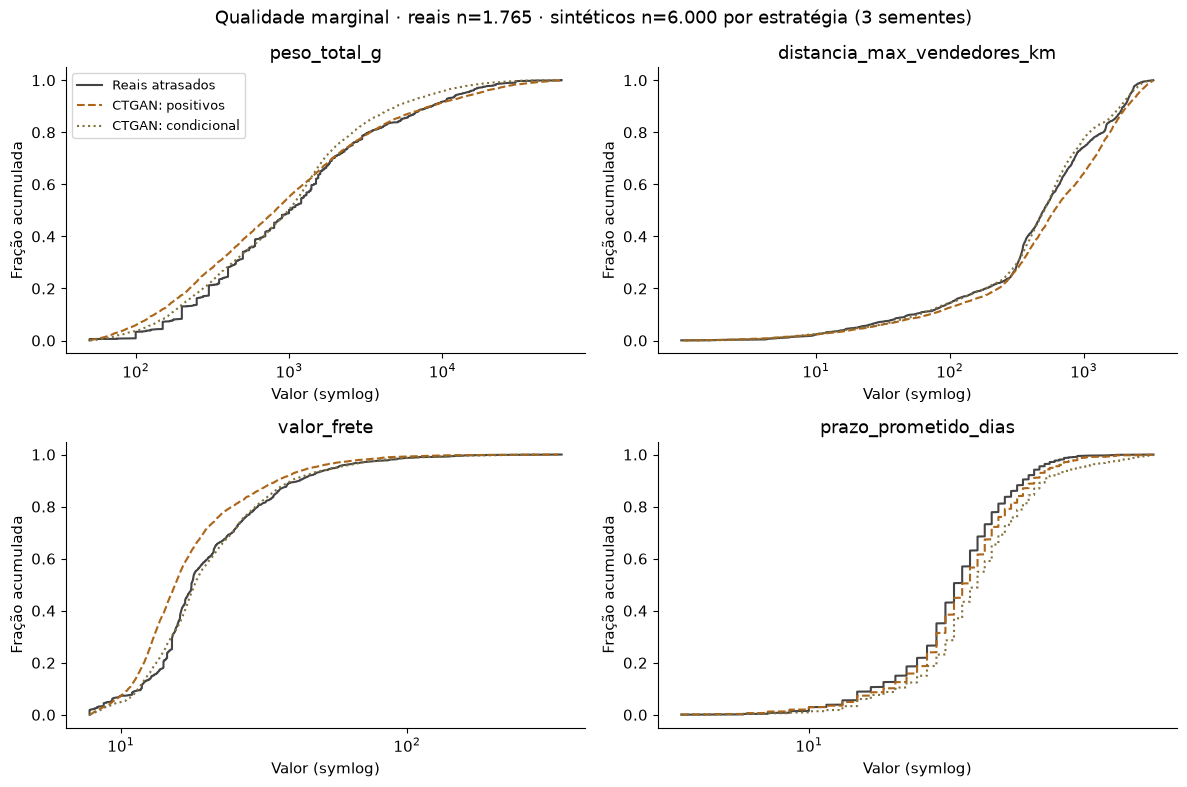

,grupo,n,diferenca_mediana_R$,fracao_diferenca_maior_1pct
0,Atrasos reais de treino,1764,0.0000,0.0011
1,CTGAN: positivos,5932,80.8534,0.9944
2,CTGAN: condicional,5999,88.8764,0.9925


In [6]:
reais_pos = base.loc[base.particao.eq('treino') & base.atrasou.eq(1)]
lotes = {}
for metodo in ['CTGAN_positivos', 'CTGAN_condicional']:
    lotes[metodo] = pd.concat([joblib.load(pasta / f'gerador_{metodo}_{s}.joblib')['sinteticos']
                              for s in [7, 42, 123]], ignore_index=True)
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
for coluna, ax in zip(atributos, eixos.ravel()):
    series = [('Reais atrasados', reais_pos[coluna], '#444444', '-')]
    series += [(nomes[m], t[coluna], cores[m], est) for (m, t), est in zip(lotes.items(), ['--', ':'])]
    for nome, serie, cor, estilo in series:
        xs = np.sort(serie.dropna().to_numpy())
        ax.plot(xs, np.arange(1, len(xs)+1)/len(xs), color=cor, linestyle=estilo, label=nome)
    ax.set(xscale='symlog', title=coluna, xlabel='Valor (symlog)', ylabel='Fração acumulada')
eixos[0, 0].legend(fontsize=9)
fig.suptitle('Qualidade marginal · reais n=1.765 · sintéticos n=6.000 por estratégia (3 sementes)')
fig.tight_layout()
fig.savefig(pasta / 'qualidade_doses.png', dpi=150, bbox_inches='tight')
plt.show()

# Diagnóstico de relação monetária: não usado para selecionar dados ou ajustar modelos.
diagnostico_monetario = []
for nome, t in [('Atrasos reais de treino', reais_pos), *[(nomes[m], t) for m, t in lotes.items()]]:
    soma = t.valor_itens + t.valor_frete
    diferenca = (t.valor_pago - soma).abs()
    validos = soma.notna() & t.valor_pago.notna() & soma.gt(0)
    diagnostico_monetario.append({'grupo': nome, 'n': int(validos.sum()),
        'diferenca_mediana_R$': diferenca[validos].median(),
        'fracao_diferenca_maior_1pct': (diferenca[validos] > .01*soma[validos]).mean()})
diagnostico_monetario = pd.DataFrame(diagnostico_monetario)
diagnostico_monetario.to_csv(pasta / 'qualidade_relacao_monetaria.csv', index=False)
display(diagnostico_monetario.round(4))

### 6. Teste real — relato descritivo com limiares congelados

Os 25.550 pedidos de teste não receberam dados artificiais. O treino não foi refeito com a validação.
A mesma configuração escolhida pela validação é relatada aqui, mesmo se outra obtiver resultado
maior no teste. Nenhuma escolha automática de “melhor semente”.

In [7]:
display(tabela_legivel(resumo_teste))
selecao = evidencias['selecao']
display(tabela_legivel(resumo_teste.loc[(resumo_teste.metodo.eq(selecao['metodo'])) &
                                       (resumo_teste.dose.eq(selecao['dose']))]))
print('Baseline de sempre prever no prazo: accuracy', f'{1-base.loc[base.particao.eq("teste"), "atrasou"].mean():.2%}',
      '| F1 da classe atraso = 0.')

,Método,Adicionados,Accuracy,Precision,Recall,F1,AP,Atrasos na fila
0,CTGAN: condicional,500,67.93%,8.09%,60.68%,14.27%,0.0860,266.3
1,CTGAN: condicional,1000,63.80%,7.20%,60.50%,12.86%,0.0742,225.0
2,CTGAN: condicional,2000,58.50%,5.87%,55.81%,10.62%,0.0601,180.0
3,CTGAN: positivos,500,65.56%,8.09%,65.87%,14.41%,0.0925,280.7
4,CTGAN: positivos,1000,66.29%,8.04%,63.67%,14.27%,0.0901,278.3
5,CTGAN: positivos,2000,66.96%,7.95%,61.27%,14.06%,0.0847,255.3
6,Somente reais,0,68.36%,8.47%,63.17%,14.94%,0.0963,288.0
7,Repetição,500,67.34%,8.33%,63.97%,14.73%,0.0950,285.3
8,Repetição,1000,67.00%,8.31%,64.77%,14.73%,0.0939,283.7
9,Repetição,2000,64.60%,7.94%,66.55%,14.19%,0.0921,280.0


,Método,Adicionados,Accuracy,Precision,Recall,F1,AP,Atrasos na fila
6,Somente reais,0,68.36%,8.47%,63.17%,14.94%,0.0963,288.0


Baseline de sempre prever no prazo: accuracy 95.60% | F1 da classe atraso = 0.


### 7. Matrizes — baseline e melhor configuração CTGAN pela validação

A configuração CTGAN abaixo é selecionada por **média de F1 na validação**, mesmo que não supere
o baseline. Suas matrizes são médias das três sementes; as contagens exatas por execução estão nos CSVs.
As decisões usam o limiar F1, e não a fila fixa de 10%.

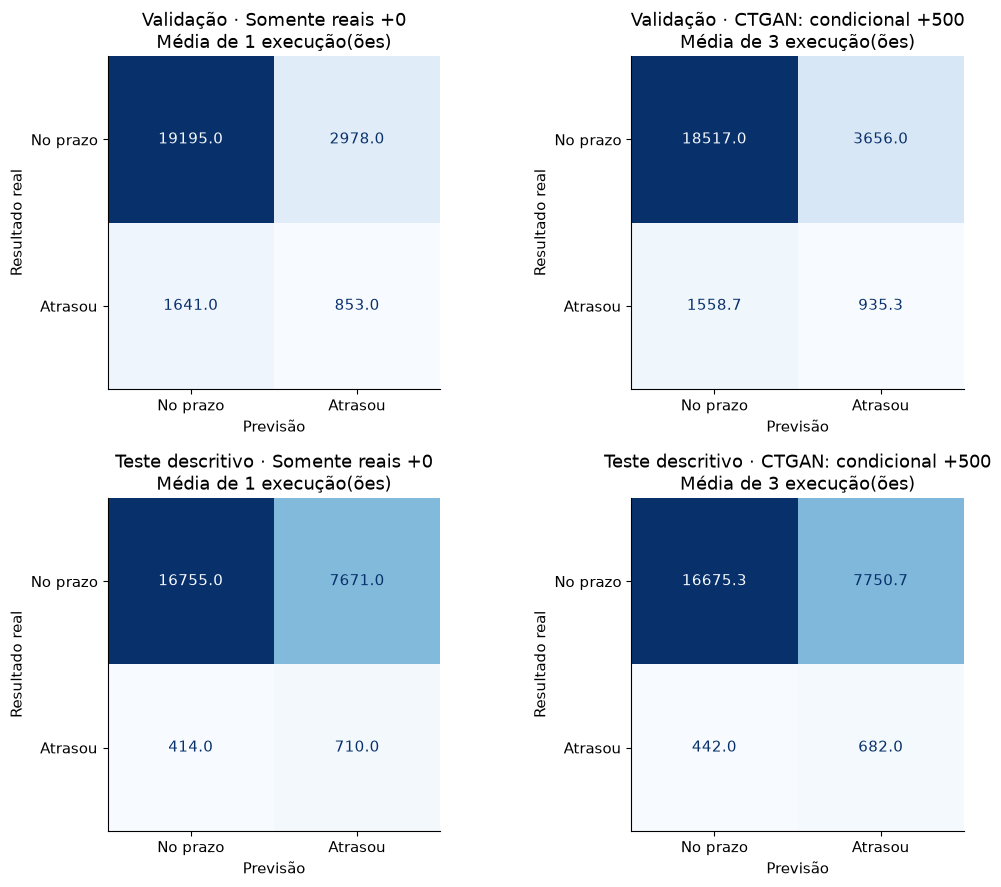

In [8]:
melhor_gan = resumo_val.loc[resumo_val.metodo.str.startswith('CTGAN')].sort_values(
    ['f1_mean', 'AP_mean'], ascending=False).iloc[0]
fig, eixos = plt.subplots(2, 2, figsize=(11, 9))
for linha, (tabela, parte) in enumerate([(val, 'Validação'), (teste, 'Teste descritivo')]):
    for coluna, (metodo, dose) in enumerate([('Real', 0), (melhor_gan.metodo, melhor_gan.dose)]):
        r = tabela.loc[tabela.metodo.eq(metodo) & tabela.dose.eq(dose)]
        cm = r[['tn', 'fp', 'fn', 'tp']].mean().to_numpy().reshape(2, 2)
        ConfusionMatrixDisplay(cm, display_labels=['No prazo', 'Atrasou']).plot(
            ax=eixos[linha, coluna], colorbar=False, cmap='Blues', values_format='.1f')
        eixos[linha, coluna].set(title=f'{parte} · {nomes[metodo]} +{int(dose)}' + chr(10) + f'Média de {len(r)} execução(ões)',
                                xlabel='Previsão', ylabel='Resultado real')
fig.tight_layout()
fig.savefig(pasta / 'matrizes_doses.png', dpi=150, bbox_inches='tight')
plt.show()

### 8. Conferir métricas, identidade dos pedidos e ausência de vazamento

In [9]:
checks = []
limite_threads = threadpool_limits(limits=4)
for parte, tabela in [('validacao', val), ('teste', teste)]:
    dados_parte = base.loc[base.particao.eq(parte)].reset_index(drop=True)
    alvo = dados_parte.atrasou.to_numpy(dtype=int)
    matriz = evidencias['preprocessador'].transform(dados_parte[COLUNAS_PREVISAO]).astype(np.float32)
    for chave, pacote in evidencias['modelos'].items():
        scores = pacote['scores_validacao' if parte == 'validacao' else 'scores_teste']
        reproduzidos = pacote['modelo'].predict_proba(matriz)[:, 1]
        np.testing.assert_allclose(scores, reproduzidos, rtol=1e-10, atol=1e-12)
        recalculado = metricas(alvo, scores, pacote['limiar'])
        linha = tabela.loc[tabela.metodo.eq(pacote['metodo']) & tabela.dose.eq(pacote['dose']) &
                           tabela.semente.eq(pacote['semente'])].iloc[0]
        assert all(np.isclose(linha[k], v) for k, v in recalculado.items())
        assert int(linha.tn + linha.fp + linha.fn + linha.tp) == len(alvo)
        checks.append({'particao': parte, 'execucao': chave, 'metricas_recalculadas': True})
for metodo in ['CTGAN_positivos', 'CTGAN_condicional']:
    for s in [7, 42, 123]:
        lote = joblib.load(pasta / f'gerador_{metodo}_{s}.joblib')['sinteticos']
        assert len(lote) == 2000
        validar_injecao(base, lote)
assert base.origem_dado.eq('real_olist').all() and base.order_id.is_unique
pd.DataFrame(checks).to_csv(pasta / 'conferencia_metricas.csv', index=False)
print(f'Conferência aprovada: {len(checks)} avaliações e scores reproduzidos; seis lotes sintéticos isolados.')

Conferência aprovada: 56 avaliações e scores reproduzidos; seis lotes sintéticos isolados.


## Como interpretar e decidir

1. Comparar a média e a variação entre sementes, sem escolher a execução mais favorável.
2. Separar F1 com limiar ajustado da operação com fila limitada a 10%.
3. Exigir melhora consistente em pedidos reais; distribuição plausível sozinha não basta.
4. Se o aumento artificial piorar os resultados, conservar o treino real e investigar atributos
   disponíveis na aprovação, definição/coorte dos rótulos e mudanças entre períodos.
5. Uma rodada com cerca de 900 atualizações não esgota a CTGAN condicional. Também não justifica
   aumentar indefinidamente o treino sem evidência. Registrar qualquer próximo experimento antes da avaliação.

Fontes técnicas: [CTGAN](https://arxiv.org/abs/1907.00503),
[amostragem condicional](https://docs.sdv.dev/sdv/sampling/conditional/single-table.md),
[vazamento por reamostragem](https://imbalanced-learn.org/stable/common_pitfalls.html).